### 实验3 卷积神经网络计算机视觉基础 (2 CIFAR-10)

#### 一、基本实现过程
##### 1.1 基本设置
（1）导入torch等第三方库


In [ ]:
import random
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F # 函数式接口模块
from torch.utils.data import DataLoader, Subset # 数据集组织，以便后面batch划分
import torch.optim as optim # 优化器

import json
import time
from pathlib import Path
# 将训练历史、验证结果和测试比较表按表格格式显示。
from IPython.display import display
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# 所有结果放在当前实验目录下，重复运行时覆盖同名结果。
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
torch.set_num_threads(4) # 限制CPU线程数，避免共享环境中占用过多线程


（2）设置图表显示

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # 导入刻度格式化模块
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC']  # 支持中文字体
plt.rcParams['figure.dpi'] = 300   # Notebook 中显示的清晰度
plt.rcParams['savefig.dpi'] = 300  # 保存图片的清晰度
plt.rcParams['font.size'] = 12

（3）观察设备情况，以便后面使用GPU

In [3]:
# 优先选用GPU，训练和测试阶段都使用这一设备。
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"正在使用的设备: {device}")

正在使用的设备: cuda


（4）设置固定随机种子，以便复现

In [ ]:
# 设置随机种子（不含对batch划分的设置）
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)                # PyTorch CPU随机数
    torch.cuda.manual_seed(seed)           # PyTorch 当前GPU随机数
    torch.cuda.manual_seed_all(seed)       # PyTorch 所有GPU随机数
    torch.backends.cudnn.deterministic = True # 强制CuDNN使用确定性算法
    torch.backends.cudnn.benchmark = False # 关闭CuDNN的自动寻找最优算法

set_seed(42)

##### 1.2 数据导入与预处理
（1）导入数据集并观察形状

In [ ]:
import tarfile

tar_path = './data/cifar-10-batches-py.tar.gz'
if not Path('data/cifar-10-batches-py').is_dir():
    with tarfile.open(tar_path, 'r:gz') as tar:
        tar.extractall('./data', filter='data')

In [6]:
# 统一图像变换，固定训练／验证划分，并按batch组织数据。
from torchvision import datasets, transforms

# 训练、验证、测试使用相同的预处理。
transform = transforms.Compose([
    transforms.ToTensor(), # 将H×W×C图像转为C×H×W浮点张量，像素缩放到[0, 1]
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # 三通道统一缩放至[-1, 1]
])

full_train_dataset = datasets.CIFAR10(
    root='./data', train=True, transform=transform, download=False
)
test_dataset = datasets.CIFAR10(
    root='./data', train=False, transform=transform, download=False
)

# 从原训练集中分层抽取 20% 为固定验证集；只划分一次。
val_ratio = 0.2
train_indices, val_indices = train_test_split(
    np.arange(len(full_train_dataset)), test_size=val_ratio,
    random_state=42, stratify=full_train_dataset.targets
)
# Subset只保存划分索引，训练和验证数据不会重叠。
train_dataset = Subset(full_train_dataset, train_indices.tolist())
val_dataset = Subset(full_train_dataset, val_indices.tolist())

# 多进程完成原有图像变换，CPU 张量按 batch 传入 GPU。
loader_options = {'num_workers': 2, 'persistent_workers': True,
                  'pin_memory': device.type == 'cuda'}
g = torch.Generator().manual_seed(42)
# 训练时打乱样本；计算训练、验证和测试指标时保持固定顺序。
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, generator=g, **loader_options)
train_eval_loader = DataLoader(train_dataset, batch_size=64, shuffle=False, **loader_options)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, **loader_options)


In [7]:
# 检查三个数据子集的样本数和单张RGB图像的通道、尺寸。
print(f"训练集样本数: {len(train_dataset)}")
print(f"验证集样本数: {len(val_dataset)}")
print(f"测试集样本数: {len(test_dataset)}")
print(f"单张图片形状: {tuple(train_dataset[0][0].shape)}")

训练集样本数: 40000
验证集样本数: 10000
测试集样本数: 10000
单张图片形状: (3, 32, 32)


##### 1.3 基础网络结构定义与模型训练
（1）基础结构：Conv(3→32)→Pool→Conv(32→64)→Pool→Flatten→Linear(4096→128→10)。
两次2×2池化将32×32缩小到8×8；所有卷积均为3×3、padding=1，激活为ReLU。


In [8]:
# 定义基础CNN，两次池化后将32×32图像特征缩小为8×8。
# 自定义CNN结构
class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        # 第一层卷积：3个输入通道，32个输出通道
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # 第二层卷积：32个输入通道，64个输出通道
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        # 最大池化：尺寸缩小一半
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # 全连接层
        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # 第一组卷积 + 激活 + 池化
        x = self.conv1(x)
        x = F.relu(x)
        x = self.pool(x)
        
        # 第二组卷积 + 激活 + 池化
        x = self.conv2(x)
        x = F.relu(x)
        x = self.pool(x)

        # 展平
        x = torch.flatten(x, start_dim=1)

        # 全连接分类
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


（2）创建model对象，设置loss函数与优化器

In [9]:
# 为基础CNN创建交叉熵损失和Adam优化器。
model = CNN().to(device) # 基础模型
criterion = nn.CrossEntropyLoss() # 交叉熵损失
optimizer = optim.Adam(model.parameters(), lr=0.001) # 延续原代码的优化器


（3）训练并记录每轮训练集和固定验证集指标，按验证集选择最佳权重。
三种结构均使用Adam、学习率0.001、batch=64、15轮；保持相同数据划分、预处理和batch顺序。每个模型独立初始化和创建优化器。


In [10]:
# 训练各候选CNN，记录每轮指标，并恢复最佳验证轮次。
def train_model(model, epochs, batch, optimizer, run_name):
    model = model.to(device)
    # 每个模型重新设置相同的 batch 顺序，保证结构对比的条件一致。
    train_loader.generator = torch.Generator().manual_seed(42)
    # 采样器另有随机数生成器，需要一并重置才能统一各模型的batch顺序。
    train_loader.sampler.generator = torch.Generator().manual_seed(42)
    # 记录每轮结果，并初始化最佳验证指标。
    loss_result = []
    best_acc, best_loss, best_epoch = -1.0, float('inf'), 0
    checkpoint = OUTPUT_DIR / f'{run_name}_best.pt'
    # GPU运算是异步的，同步后再开始计时。
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()

    for epoch in range(epochs):
        model.train() # 切换为训练模式，允许参数通过梯度更新
        for batch_x, batch_y in train_loader:
            # 图像与标签必须和模型位于同一设备。
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad() # 清空上一批次残留的梯度
            preds_y = model(batch_x) # 前向传播，输出各类别的logits
            loss_train = criterion(preds_y, batch_y)
            loss_train.backward() # 反向传播，计算各参数的梯度
            optimizer.step() # 根据梯度更新当前模型的参数

        # 同一个 epoch 结束后，在 eval 模式下计算训练集和验证集指标。
        epoch_result = {'Epoch': epoch + 1}
        model.eval()
        with torch.no_grad():
            for split, loader in [('Train', train_eval_loader), ('Val', val_loader)]:
                total_loss_sum, correct, sample_num = 0.0, 0, 0
                for batch_x, batch_y in loader:
                    batch_x = batch_x.to(device)
                    batch_y = batch_y.to(device)
                    preds_y = model(batch_x)
                    loss = criterion(preds_y, batch_y)
                    # 按批次样本数加权，避免最后一个小batch影响平均Loss。
                    total_loss_sum += loss.item() * batch_y.size(0)
                    correct += (preds_y.argmax(dim=1) == batch_y).sum().item()
                    sample_num += batch_y.size(0)
                epoch_result[f'{split}_Loss'] = total_loss_sum / sample_num
                epoch_result[f'{split}_Acc'] = correct / sample_num

        # 仅依据验证集选权重；准确率相同时，选择验证 Loss 较小的轮次。
        val_acc, val_loss = epoch_result['Val_Acc'], epoch_result['Val_Loss']
        if val_acc > best_acc or (val_acc == best_acc and val_loss < best_loss):
            best_acc, best_loss, best_epoch = val_acc, val_loss, epoch + 1
            torch.save(model.state_dict(), checkpoint)

        loss_result.append(epoch_result)
        print(
            f"{run_name} | Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {epoch_result['Train_Loss']:.4f}, "
            f"Train Acc: {epoch_result['Train_Acc']:.2%} | "
            f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2%}", flush=True
        )

    if device.type == 'cuda':
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    # 训练结束后恢复最佳验证轮次，后面的测试及保存均使用这组权重。
    model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    model.eval()
    # 保存比较表需要的最佳轮次与耗时，并把完整历史写入CSV。
    model.best_epoch = best_epoch
    model.training_seconds = seconds
    history = pd.DataFrame(loss_result)
    history.to_csv(OUTPUT_DIR / f'{run_name}_history.csv', index=False)
    print(f'{run_name}: 最佳轮次 {best_epoch}，验证 Acc {best_acc:.2%}，耗时 {seconds:.1f}s')
    return history


In [11]:
# 按统一超参数训练基础模型，保存结构对比所需的记录。
train_result_df = train_model(model, epochs=15, batch=64, optimizer=optimizer, run_name='CNN')
display(train_result_df.style.format({
    'Train_Loss': '{:.4f}', 'Train_Acc': '{:.2%}',
    'Val_Loss': '{:.4f}', 'Val_Acc': '{:.2%}'
}).hide(axis='index'))
models = {'CNN': model}
results_dict = {'CNN': train_result_df}


CNN | Epoch 1/15 | Train Loss: 1.0930, Train Acc: 61.35% | Val Loss: 1.1411, Val Acc: 59.89%


CNN | Epoch 2/15 | Train Loss: 0.8934, Train Acc: 68.51% | Val Loss: 0.9959, Val Acc: 64.61%


CNN | Epoch 3/15 | Train Loss: 0.7716, Train Acc: 72.97% | Val Loss: 0.9279, Val Acc: 67.63%


CNN | Epoch 4/15 | Train Loss: 0.6509, Train Acc: 77.15% | Val Loss: 0.8998, Val Acc: 68.48%


CNN | Epoch 5/15 | Train Loss: 0.5194, Train Acc: 82.22% | Val Loss: 0.8716, Val Acc: 70.28%


CNN | Epoch 6/15 | Train Loss: 0.4569, Train Acc: 84.42% | Val Loss: 0.9060, Val Acc: 70.41%


... (7 outputs left out)

CNN | Epoch 14/15 | Train Loss: 0.0853, Train Acc: 97.10% | Val Loss: 1.6550, Val Acc: 69.74%


CNN | Epoch 15/15 | Train Loss: 0.1164, Train Acc: 95.79% | Val Loss: 1.8476, Val Acc: 68.41%


CNN: 最佳轮次 6，验证 Acc 70.41%，耗时 33.1s


Epoch,Train_Loss,Train_Acc,Val_Loss,Val_Acc
1,1.0930,61.35%,1.1411,59.89%
2,0.8934,68.51%,0.9959,64.61%
3,0.7716,72.97%,0.9279,67.63%
4,0.6509,77.15%,0.8998,68.48%
5,0.5194,82.22%,0.8716,70.28%
6,0.4569,84.42%,0.9060,70.41%
7,0.4393,84.21%,0.9868,68.77%
8,0.3151,89.58%,0.9836,69.50%
9,0.2158,93.23%,1.0583,70.21%
10,0.1623,95.05%,1.1583,70.11%


（4）绘制 Baseline 的训练集、验证集 Loss 与 Acc 曲线，查看收敛和泛化情况

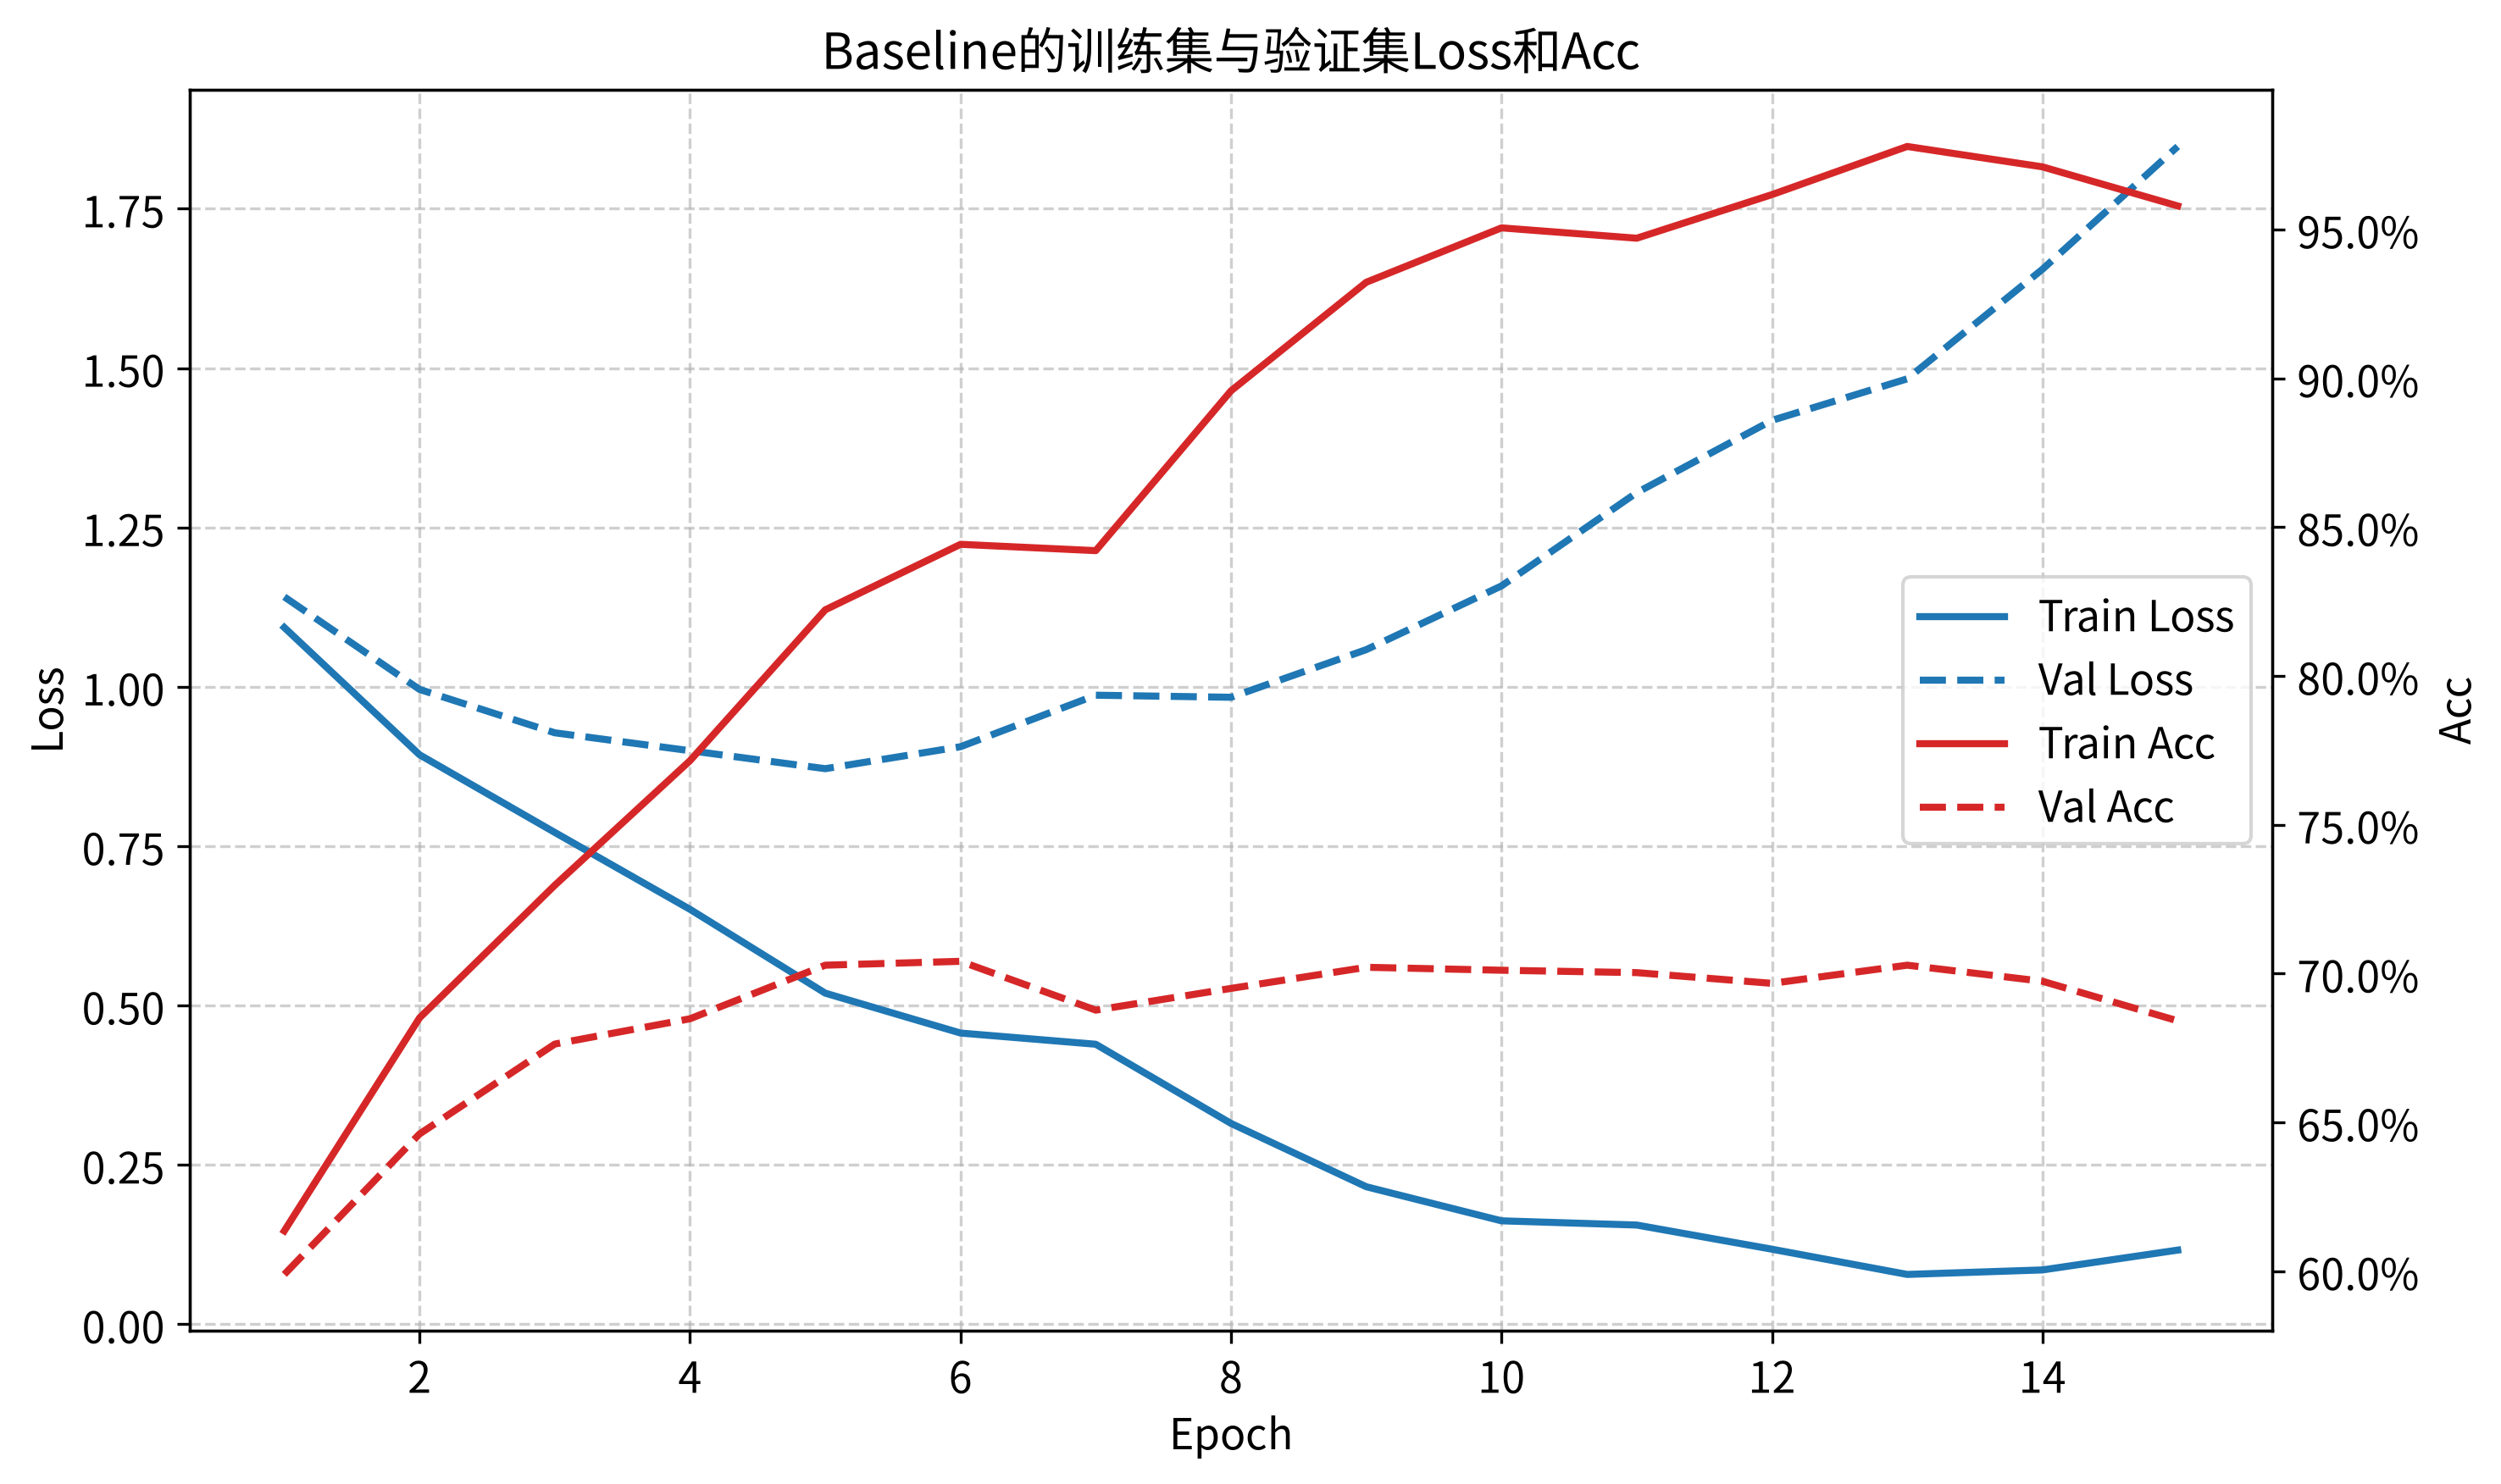

In [12]:
# 同时绘制基础模型的训练和验证指标，检查是否开始过拟合。
# 分别绘制训练集、验证集的 Loss 与 Acc（实线：训练；虚线：验证）。
epochs = range(1, len(train_result_df) + 1)
fig, ax1 = plt.subplots(figsize=(10, 6))

line1 = ax1.plot(epochs, train_result_df['Train_Loss'],
                 label='Train Loss', color='tab:blue', linewidth=2)
line2 = ax1.plot(epochs, train_result_df['Val_Loss'],
                 label='Val Loss', color='tab:blue', linestyle='--', linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2 = ax1.twinx()
line3 = ax2.plot(epochs, train_result_df['Train_Acc'],
                 label='Train Acc', color='tab:red', linewidth=2)
line4 = ax2.plot(epochs, train_result_df['Val_Acc'],
                 label='Val Acc', color='tab:red', linestyle='--', linewidth=2)
ax2.set_ylabel('Acc', fontsize=12)
ax2.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=1))

lines = line1 + line2 + line3 + line4
ax1.legend(lines, [line.get_label() for line in lines], loc='center right', fontsize=12)
plt.title('Baseline的训练集与验证集Loss和Acc', fontsize=14)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'baseline_curves.png', bbox_inches='tight')
plt.show()


#### 二、不同卷积结构的对照实验
（1）在基础模型上比较两种改动，其余训练条件相同。

| 名称 | 卷积结构 | 展平后维度 | 全连接分类器 |
| :--- | :--- | :--- | :--- |
| CNN | Conv32→Pool→Conv64→Pool | 64×8×8 | 128→10 |
| CNN3 | Conv32→Pool→Conv64→Pool→Conv128→Pool | 128×4×4 | 128→10 |
| CNNDouble | Conv32→Conv32→Pool→Conv64→Conv64→Pool | 64×8×8 | 128→10 |

CNN3对应“在全连接分类器前增加卷积块”；CNNDouble对应“在每个卷积块的Pooling前增加一个卷积”。所有模型不加额外的数据增强、Dropout或BatchNorm，以集中观察结构变化。


In [13]:
# 在基础CNN上定义两种扩展结构，并分别独立初始化和训练。
# 方案一：在第二次池化后、全连接分类器前增加第三个卷积块。
class CNN3(CNN):
    def __init__(self):
        super(CNN3, self).__init__()
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(128 * 4 * 4, 128) # 第三次池化后为128×4×4

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        # 额外卷积块组合高层特征，再把空间尺寸从8×8缩小为4×4。
        x = self.pool(F.relu(self.conv3(x)))
        x = torch.flatten(x, start_dim=1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

# 方案二：每次池化前增加一层同通道卷积，池化位置保持不变。
class CNNDouble(CNN):
    def __init__(self):
        super(CNNDouble, self).__init__()
        # 新增卷积保持通道数和空间尺寸，继续复用基础模型的分类器。
        self.conv1_extra = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.conv2_extra = nn.Conv2d(64, 64, kernel_size=3, padding=1)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        # 在池化降采样前增加一次局部特征提取。
        x = self.pool(F.relu(self.conv1_extra(x)))
        x = F.relu(self.conv2(x))
        x = self.pool(F.relu(self.conv2_extra(x)))
        x = torch.flatten(x, start_dim=1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

model_classes = {'CNN': CNN, 'CNN3': CNN3, 'CNNDouble': CNNDouble}
# 每种结构独立初始化并创建优化器，避免沿用其他模型的参数状态。
for name in ['CNN3', 'CNNDouble']:
    set_seed(42)
    current_model = model_classes[name]().to(device)
    current_optimizer = optim.Adam(current_model.parameters(), lr=0.001)
    result = train_model(current_model, epochs=15, batch=64,
                         optimizer=current_optimizer, run_name=name)
    # 保存各自恢复最佳权重后的模型与历史，用于后续统一评估。
    models[name] = current_model
    results_dict[name] = result
    display(result.style.format({
        'Train_Loss': '{:.4f}', 'Train_Acc': '{:.2%}',
        'Val_Loss': '{:.4f}', 'Val_Acc': '{:.2%}'
    }).hide(axis='index'))


CNN3 | Epoch 1/15 | Train Loss: 1.1327, Train Acc: 59.69% | Val Loss: 1.1609, Val Acc: 58.47%


CNN3 | Epoch 2/15 | Train Loss: 0.9004, Train Acc: 68.58% | Val Loss: 0.9812, Val Acc: 65.31%


CNN3 | Epoch 3/15 | Train Loss: 0.7703, Train Acc: 72.88% | Val Loss: 0.8958, Val Acc: 68.58%


CNN3 | Epoch 4/15 | Train Loss: 0.6473, Train Acc: 77.26% | Val Loss: 0.8384, Val Acc: 70.83%


CNN3 | Epoch 5/15 | Train Loss: 0.5381, Train Acc: 81.51% | Val Loss: 0.8048, Val Acc: 72.40%


CNN3 | Epoch 6/15 | Train Loss: 0.4548, Train Acc: 84.86% | Val Loss: 0.7774, Val Acc: 73.95%


... (24 outputs left out)

CNNDouble | Epoch 14/15 | Train Loss: 0.0773, Train Acc: 97.42% | Val Loss: 1.5318, Val Acc: 72.86%


CNNDouble | Epoch 15/15 | Train Loss: 0.0556, Train Acc: 98.08% | Val Loss: 1.6986, Val Acc: 73.03%


CNNDouble: 最佳轮次 6，验证 Acc 74.32%，耗时 32.4s


Epoch,Train_Loss,Train_Acc,Val_Loss,Val_Acc
1,1.1067,60.26%,1.1497,58.88%
2,0.8847,68.79%,0.9769,66.12%
3,0.6767,76.61%,0.8287,71.31%
4,0.5671,80.20%,0.8036,72.08%
5,0.4733,83.74%,0.7890,73.25%
6,0.3584,88.22%,0.7663,74.32%
7,0.2864,90.21%,0.8391,74.11%
8,0.2219,92.38%,0.9529,73.16%
9,0.1562,94.84%,1.0127,73.45%
10,0.1278,95.81%,1.1040,73.06%


（2）比较所有模型训练／验证 Loss 与 Acc，观察收敛速度和过拟合。


In [14]:
# 在相同坐标下绘制所有结构的Loss与Acc，比较收敛和泛化。
# 不同模型的训练、验证结果对比可视化，后续实验可复用。
def plot_multiple_models_train_result(results_dict, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

    # 颜色区分模型，实线和虚线分别表示训练集与验证集。
    for i, (model_name, df) in enumerate(results_dict.items()):
        color = colors[i % len(colors)]
        epochs = range(1, len(df) + 1)
        for split, linestyle in [('Train', '-'), ('Val', '--')]:
            label = f'{model_name} ({split})'
            ax1.plot(epochs, df[f'{split}_Loss'], label=label,
                     color=color, linestyle=linestyle, linewidth=2)
            ax2.plot(epochs, df[f'{split}_Acc'], label=label,
                     color=color, linestyle=linestyle, linewidth=2)

    for ax, metric in [(ax1, 'Loss'), (ax2, 'Acc')]:
        ax.set_title(f'训练集与验证集 {metric}', fontsize=14)
        ax.set_xlabel('Epoch', fontsize=12)
        ax.set_ylabel(metric, fontsize=12)
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend(fontsize=12)

    # 将准确率坐标格式化为百分数，并保存对比曲线。
    ax2.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=1))
    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / 'comparison_curves.png', bbox_inches='tight')
    plt.show()

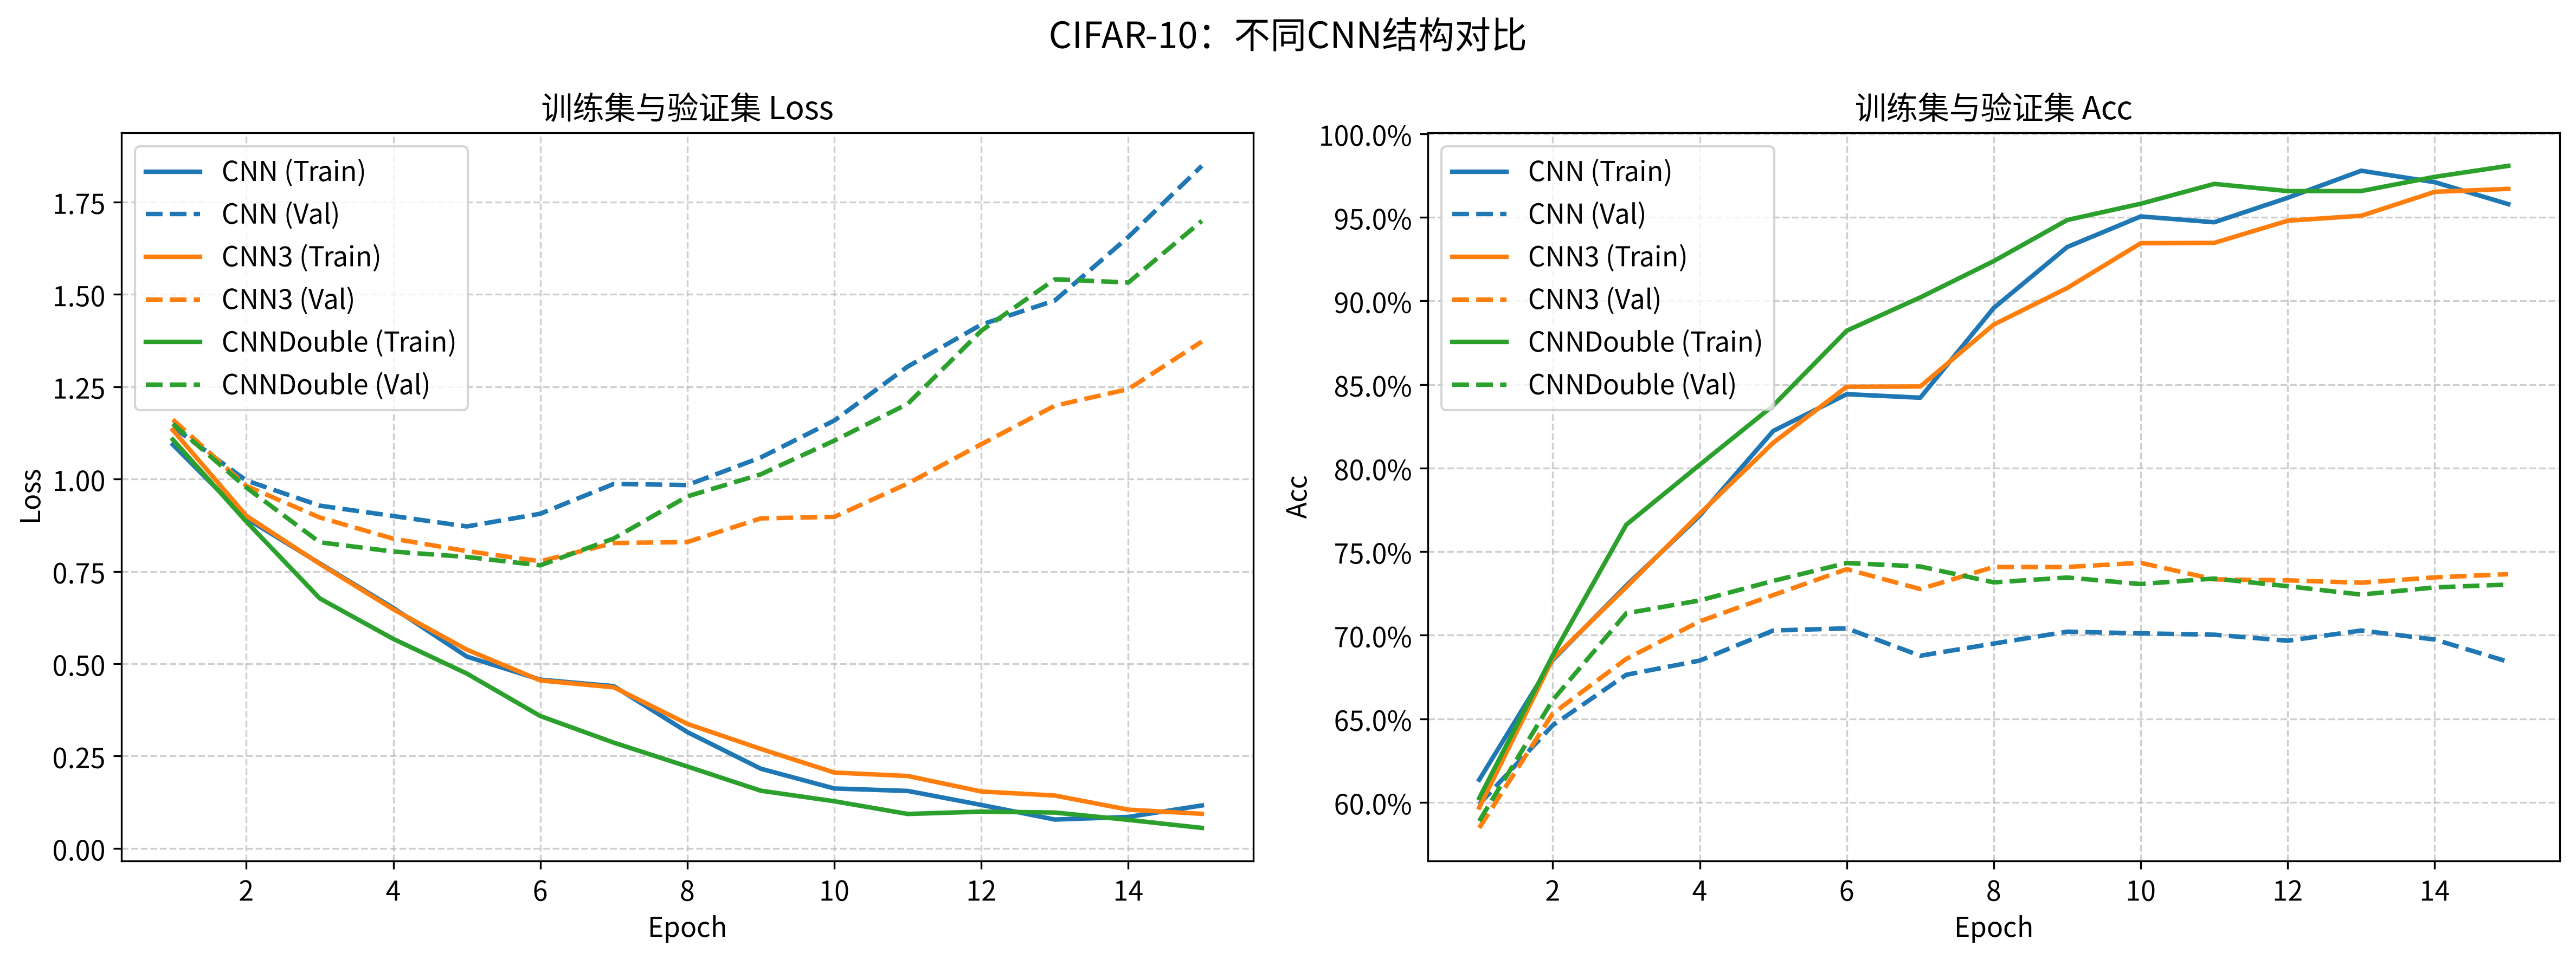

In [15]:
# 汇总基础CNN、CNN3与CNNDouble的曲线进行对照。
plot_multiple_models_train_result(results_dict, 'CIFAR-10：不同CNN结构对比')


In [16]:
# 在固定测试集上计算模型指标，并保留10个类别的预测概率。
# 对固定测试集评估；该函数只在所有候选模型与最佳轮次确定后调用。
def evaluate_model(model, batch=128):
    model.eval()
    test_correct, test_num, test_total_loss_sum = 0, 0, 0.0
    test_result, test_probs = [], []
    # 测试阶段关闭梯度计算，并按原顺序收集每个样本的预测。
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)
            test_preds = model(batch_x)
            loss = criterion(test_preds, batch_y)
            # 累计Loss总和与预测正确数，最终除以完整测试集样本数。
            test_total_loss_sum += loss.item() * batch_y.size(0)
            predicted_classes = test_preds.argmax(dim=1) # 最大logit对应预测类别
            test_correct += (predicted_classes == batch_y).sum().item()
            test_num += batch_y.size(0)
            test_result += predicted_classes.cpu().tolist()
            test_probs += test_preds.softmax(dim=1).cpu().tolist() # 仅在展示概率时使用Softmax

    # 结果表保留预测标签与10列概率，attrs中保存整体测试指标。
    result_df = pd.DataFrame(test_result, columns=['Predict'])
    prob_df = pd.DataFrame(test_probs, columns=[f'Prob_{i}' for i in range(10)])
    result_df = pd.concat([result_df, prob_df], axis=1)
    result_df.attrs['Loss'] = test_total_loss_sum / test_num
    result_df.attrs['Acc'] = test_correct / test_num
    print(f"测试集 Loss: {result_df.attrs['Loss']:.4f}，Acc: {result_df.attrs['Acc']:.2%}")
    return result_df


#### 三、验证集选模与独立测试
（1）先按最佳验证 Acc 排序（相同则比较验证 Loss），固定最终模型，再统一测试。
测试集不参与训练、最佳轮次选择或结构选择。参数量与训练时间同时列出，便于比较识别效果和计算代价。


In [17]:
# 只根据验证集结果选择最终结构，测试集不参与该选择。
validation_rows = []
for name, current_model in models.items():
    history = results_dict[name]
    # 读取训练时选中的最佳轮次，而不是直接使用最后一轮。
    best = history.iloc[current_model.best_epoch - 1]
    validation_rows.append({
        'Model': name, 'Parameters': sum(p.numel() for p in current_model.parameters()),
        'Best_Epoch': current_model.best_epoch,
        'Val_Loss': float(best['Val_Loss']), 'Val_Acc': float(best['Val_Acc']),
        'Seconds': current_model.training_seconds
    })
# 验证Acc越高越优；相同时选择验证Loss较小的结构。
validation_table = pd.DataFrame(validation_rows).sort_values(
    ['Val_Acc', 'Val_Loss'], ascending=[False, True]).reset_index(drop=True)
best_model_name = validation_table.iloc[0]['Model']
# 固定最终模型，后面的可视化和模型保存均使用它。
model = models[best_model_name]
print('按验证集选定的最终模型：', best_model_name)
display(validation_table.style.format({
    'Val_Loss': '{:.4f}', 'Val_Acc': '{:.2%}', 'Seconds': '{:.1f}'
}).hide(axis='index'))


按验证集选定的最终模型： CNN3


Model,Parameters,Best_Epoch,Val_Loss,Val_Acc,Seconds
CNN3,356810,10,0.8975,74.33%,32.3
CNNDouble,591274,6,0.7663,74.32%,32.4
CNN,545098,6,0.9060,70.41%,33.1


In [18]:
# 统一测试三种结构，保存每个模型的预测记录和比较表。
predictions, comparison_rows = {}, []
y_true = np.asarray(test_dataset.targets)
# 所有结构已按验证集定好权重，此处才开始读取测试指标。
for name, current_model in models.items():
    print('\n模型：', name)
    result = evaluate_model(current_model)
    predictions[name] = result
    result.to_csv(OUTPUT_DIR / f'{name}_test_predictions.csv', index=False)
    row = validation_table.loc[validation_table['Model'] == name].iloc[0].to_dict()
    comparison_rows.append({**row, 'Test_Loss': result.attrs['Loss'],
                            'Test_Acc': result.attrs['Acc']})
# 汇总验证与测试表现；逐样本预测另存CSV，便于检查误分类。
comparison_table = pd.DataFrame(comparison_rows)
comparison_table.to_csv(OUTPUT_DIR / 'comparison.csv', index=False)
display(comparison_table.style.format({
    'Val_Loss': '{:.4f}', 'Val_Acc': '{:.2%}', 'Test_Loss': '{:.4f}',
    'Test_Acc': '{:.2%}', 'Seconds': '{:.1f}'
}).hide(axis='index'))
test_result = predictions[best_model_name]
display(test_result.head(10).round(4))



模型： CNN


测试集 Loss: 0.9033，Acc: 70.00%

模型： CNN3


测试集 Loss: 0.8936，Acc: 74.11%

模型： CNNDouble


测试集 Loss: 0.7674，Acc: 74.53%


Model,Parameters,Best_Epoch,Val_Loss,Val_Acc,Seconds,Test_Loss,Test_Acc
CNN,545098,6,0.9060,70.41%,33.1,0.9033,70.00%
CNN3,356810,10,0.8975,74.33%,32.3,0.8936,74.11%
CNNDouble,591274,6,0.7663,74.32%,32.4,0.7674,74.53%


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,3,0.0000,0.0000,0.0000,0.8695,0.0001,0.1299,0.0004,0.0000,0.0000,0.0000
1,8,0.0000,0.0118,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.9882,0.0000
2,0,0.8415,0.0197,0.0001,0.0001,0.0002,0.0000,0.0000,0.0056,0.1156,0.0172
3,0,0.9899,0.0000,0.0043,0.0000,0.0002,0.0000,0.0000,0.0006,0.0048,0.0000
4,6,0.0000,0.0000,0.0003,0.0042,0.0059,0.0000,0.9896,0.0000,0.0000,0.0000
5,6,0.0000,0.0000,0.0001,0.0037,0.0000,0.0022,0.9940,0.0000,0.0000,0.0000
6,1,0.0000,0.9631,0.0000,0.0002,0.0000,0.0002,0.0000,0.0000,0.0000,0.0365
7,6,0.0019,0.0000,0.3219,0.0150,0.0274,0.0015,0.6318,0.0003,0.0001,0.0000
8,4,0.0001,0.0000,0.0026,0.2805,0.7138,0.0009,0.0020,0.0002,0.0000,0.0000
9,1,0.0013,0.9838,0.0000,0.0000,0.0003,0.0000,0.0001,0.0001,0.0135,0.0009


（2）查看最终模型的类别表现、混淆矩阵与部分识别结果。
对角线以外的位置表示误分类；分类报告可观察整体 Acc 是否掩盖某些类别的识别困难。


              precision    recall  f1-score   support

    airplane     0.7585    0.8040    0.7806      1000
  automobile     0.8674    0.8440    0.8555      1000
        bird     0.6230    0.6130    0.6179      1000
         cat     0.5399    0.5410    0.5405      1000
        deer     0.6897    0.7090    0.6992      1000
         dog     0.6808    0.6250    0.6517      1000
        frog     0.8000    0.8280    0.8138      1000
       horse     0.7869    0.7830    0.7850      1000
        ship     0.8244    0.8590    0.8413      1000
       truck     0.8359    0.8050    0.8202      1000

    accuracy                         0.7411     10000
   macro avg     0.7407    0.7411    0.7406     10000
weighted avg     0.7407    0.7411    0.7406     10000



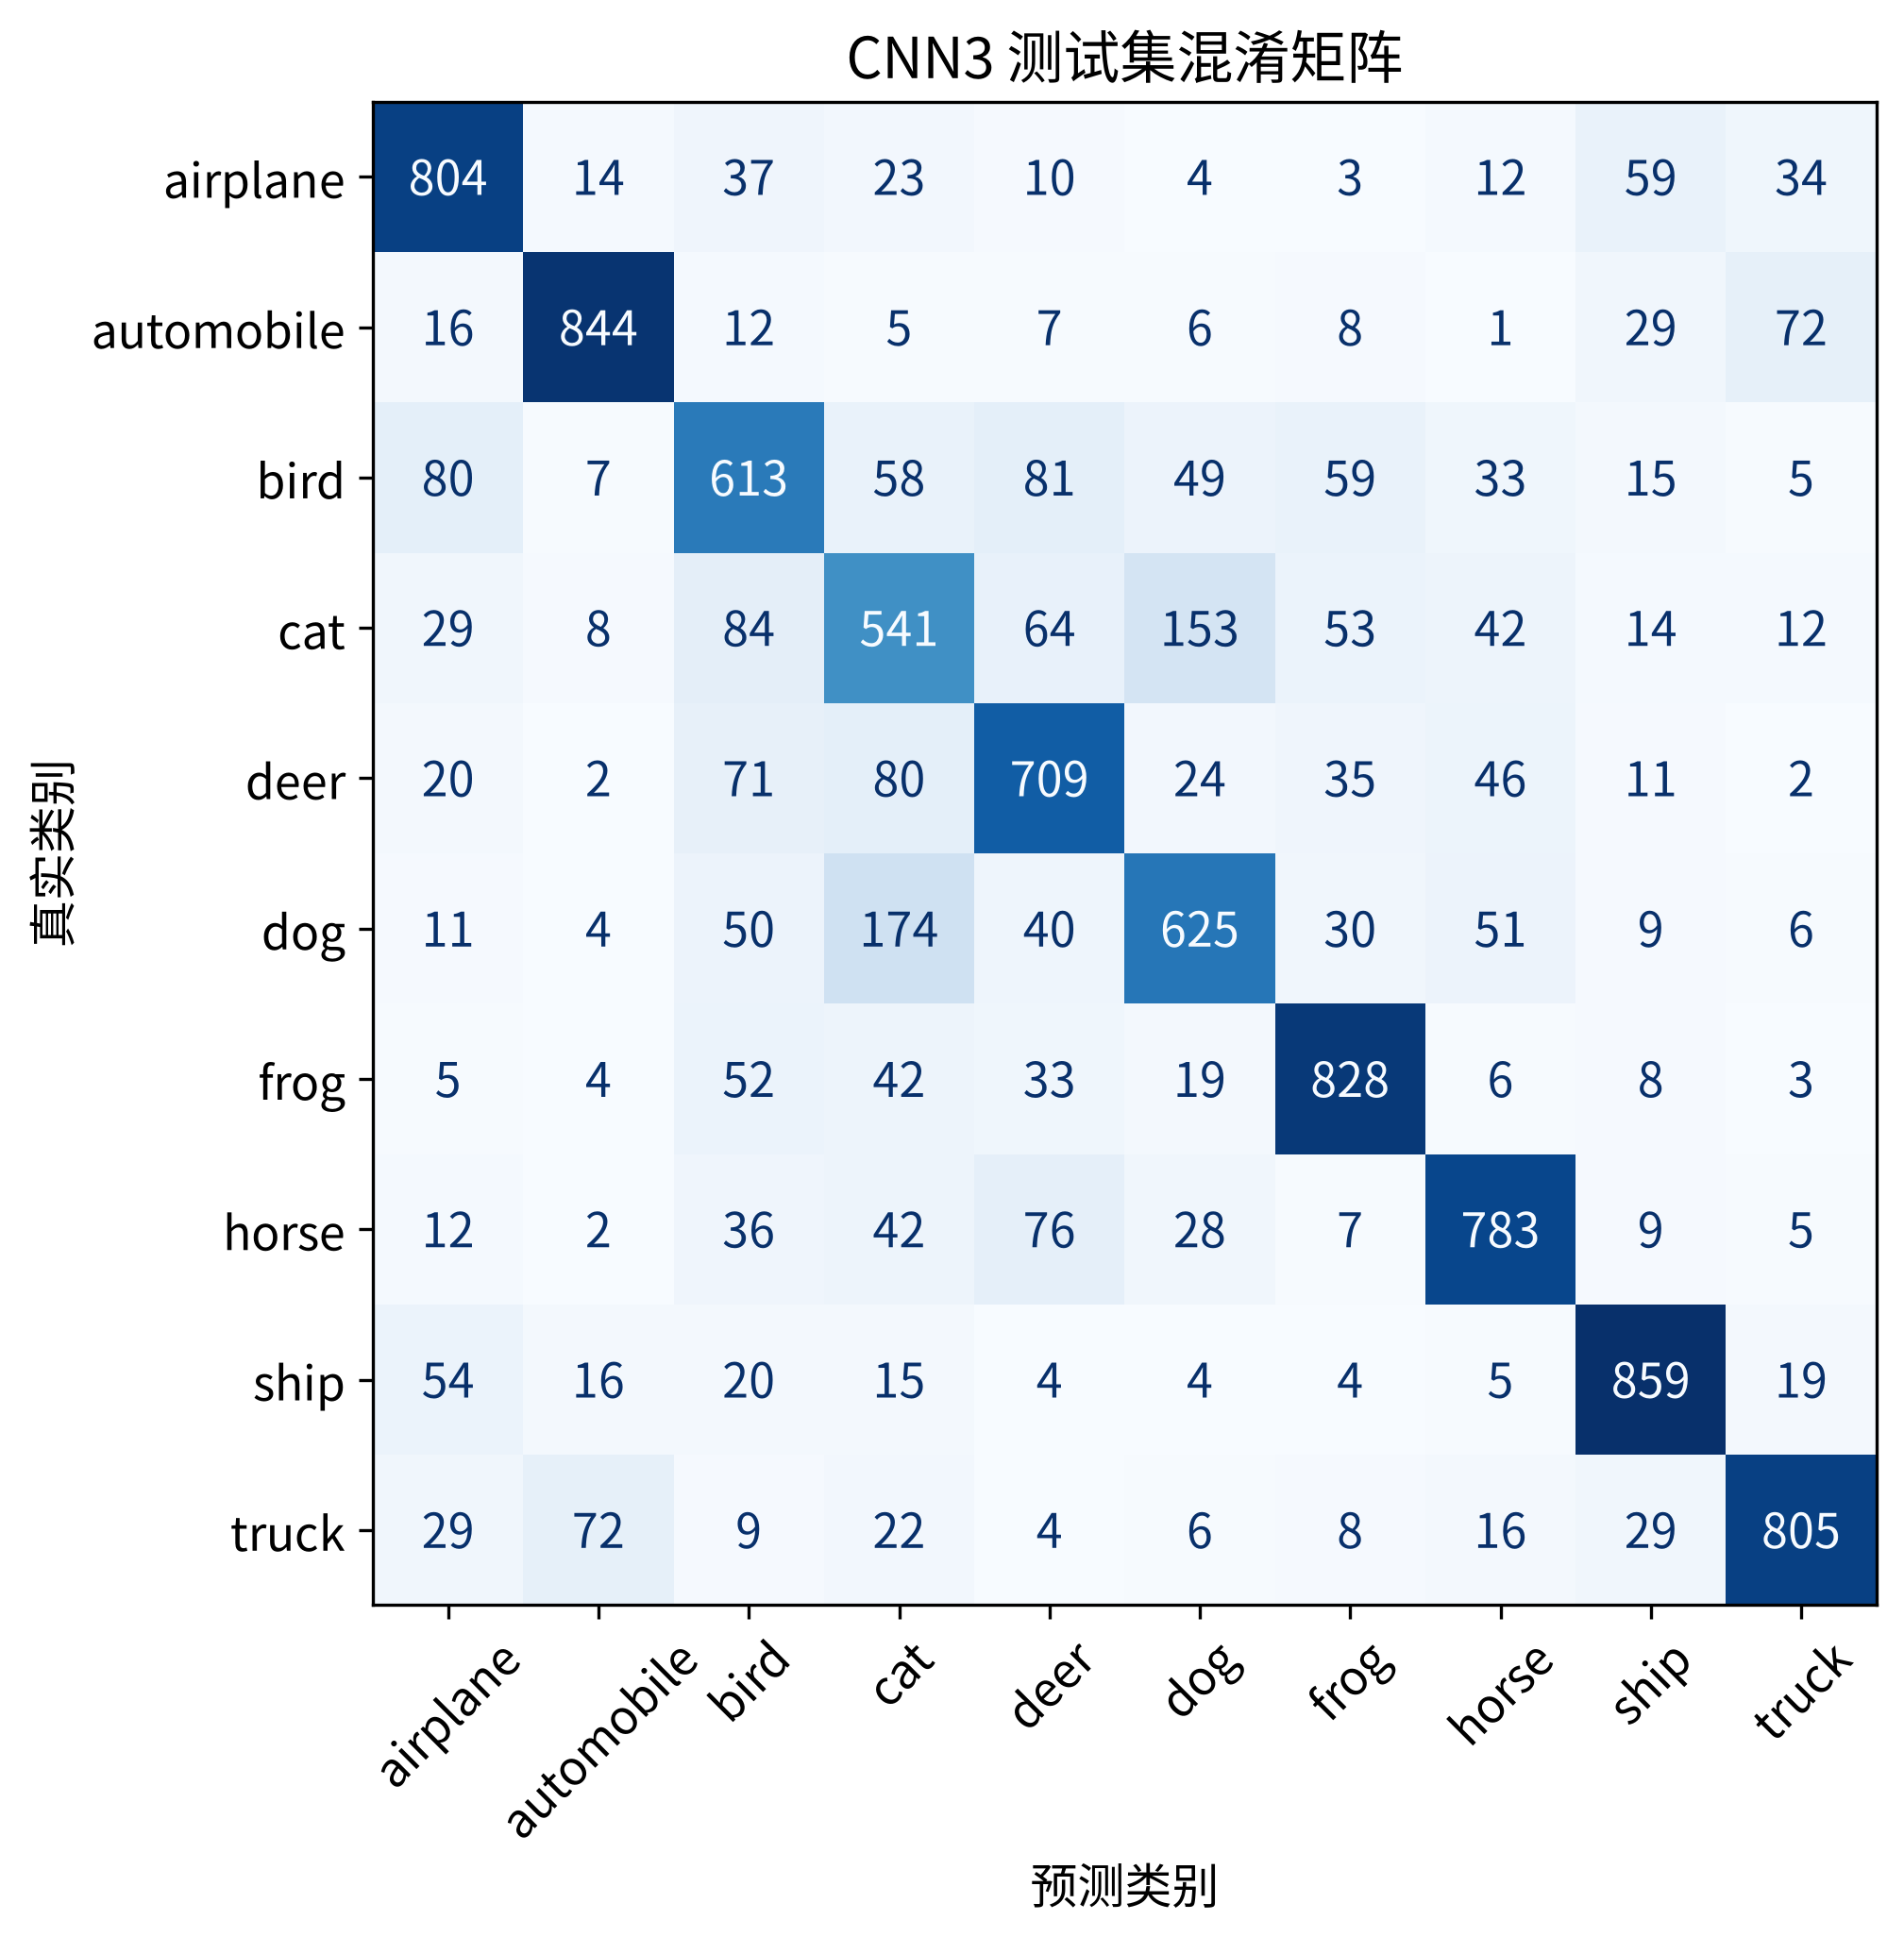

In [19]:
# 按CIFAR-10的类别顺序显示分类报告和混淆矩阵。
class_names = test_dataset.classes
# 分类报告分别给出各类别的Precision、Recall和F1。
print(classification_report(y_true, test_result['Predict'], labels=list(range(10)),
                            target_names=class_names, digits=4, zero_division=0))
fig, ax = plt.subplots(figsize=(8, 7))
# 混淆矩阵的行是真实类别，列是预测类别，非对角线表示错误。
ConfusionMatrixDisplay.from_predictions(
    y_true, test_result['Predict'], labels=list(range(10)),
    display_labels=class_names, cmap='Blues', ax=ax, colorbar=False,
    xticks_rotation=45
)
ax.set_title(f'{best_model_name} 测试集混淆矩阵')
ax.set_xlabel('预测类别')
ax.set_ylabel('真实类别')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'confusion_matrix.png', bbox_inches='tight')
plt.show()


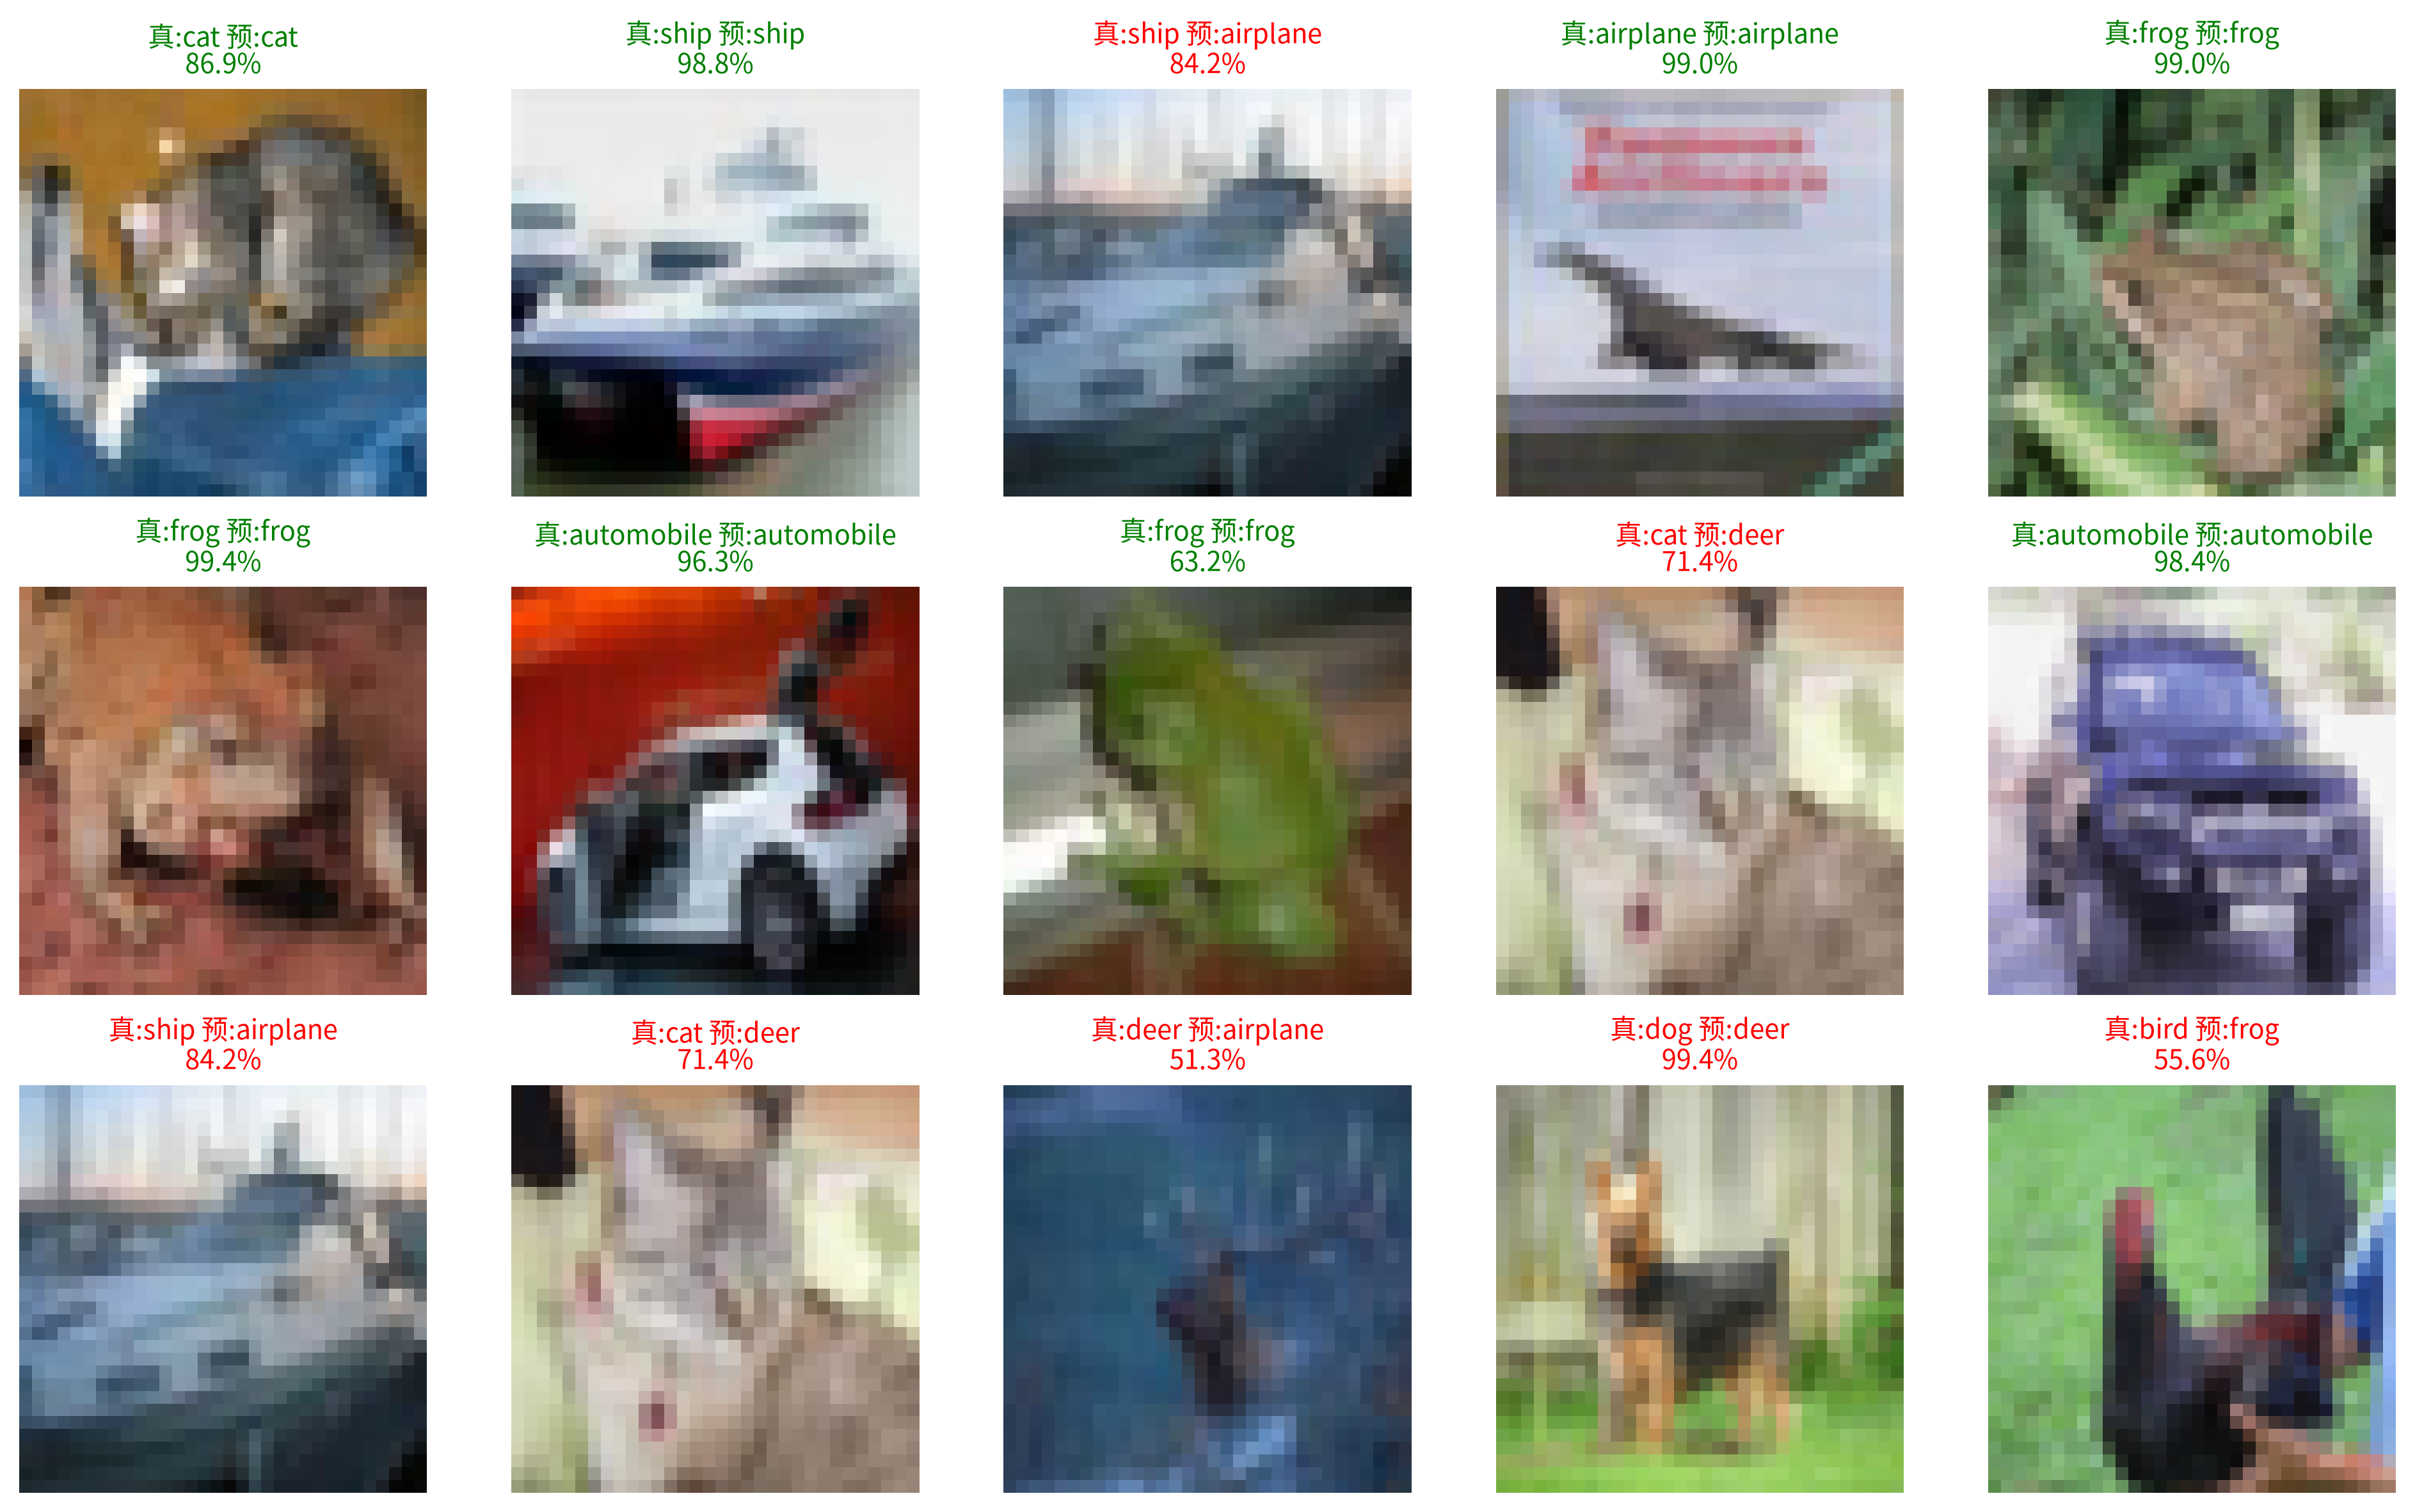

In [20]:
# 展示原始RGB测试图像，查看正确识别与误分类的具体样本。
# 前十张图与最多五张误分类样本，均来自独立测试集。
wrong = np.flatnonzero(test_result['Predict'].to_numpy() != y_true)
# 前十张图用于普通预测展示，另取最多五张误分类样本观察错误。
sample_indices = np.concatenate([np.arange(10), wrong[:5]])
fig, axes = plt.subplots(3, 5, figsize=(13, 8))
for ax in axes.flat:
    ax.axis('off')
for ax, index in zip(axes.flat, sample_indices):
    predicted = int(test_result.iloc[index]['Predict'])
    confidence = float(test_result.iloc[index][f'Prob_{predicted}']) # 预测类别的Softmax概率
    ax.imshow(test_dataset.data[index])
    # 绿色表示预测正确，红色表示误分类；高概率也可能出错。
    ax.set_title(f'真:{class_names[int(y_true[index])]} 预:{class_names[predicted]}\n{confidence:.1%}',
                 color='green' if predicted == y_true[index] else 'red', fontsize=10)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'prediction_examples.png', bbox_inches='tight')
plt.show()


（3）保存验证集选中的最终模型，并重新加载检查预测是否一致。
权重、结构名称、输入形状、预处理方式和类别顺序一并保存，后续真实图片必须使用同样的预处理。


In [21]:
# 保存最终模型的权重、结构与图像预处理配置，并检查加载结果。
experiment_config = {
    'dataset': 'CIFAR-10', 'split_sizes': [len(train_dataset), len(val_dataset), len(test_dataset)],
    'input_shape': [3, 32, 32], 'normalization': {'mean': [0.5] * 3, 'std': [0.5] * 3},
    'optimizer': 'Adam', 'learning_rate': 0.001, 'epochs': 15, 'batch': 64,
    'seed': 42, 'validation_ratio': 0.2, 'classes': class_names,
    'best_model': best_model_name, 'best_epoch': int(model.best_epoch),
    'selection': 'maximum validation accuracy; minimum validation loss for ties'
}
# 同时保存state_dict和输入配置，便于使用相同结构和预处理恢复模型。
torch.save({'model_state_dict': model.state_dict(), 'config': experiment_config},
           OUTPUT_DIR / 'best_model.pt')
# 从刚保存的文件重建模型，再在同一批输入上比较输出。
checkpoint = torch.load(OUTPUT_DIR / 'best_model.pt', map_location=device, weights_only=True)
reloaded = model_classes[checkpoint['config']['best_model']]().to(device)
reloaded.load_state_dict(checkpoint['model_state_dict'])
reloaded.eval()
with torch.no_grad():
    sample_x = next(iter(test_loader))[0][:32].to(device)
    # 加载前后logits应在浮点容差内一致，否则说明恢复过程有误。
    assert torch.allclose(model(sample_x), reloaded(sample_x), atol=1e-6)
# 保存实验配置和比较结果，作为本次实测记录。
summary = {'config': experiment_config, 'comparison': comparison_table.to_dict(orient='records')}
(OUTPUT_DIR / 'summary.json').write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('已保存并验证最佳模型：', OUTPUT_DIR / 'best_model.pt')


已保存并验证最佳模型： outputs/best_model.pt


#### 四、实验过程与模型性能分析


##### （1）三种结构的实测结果

三种模型均使用40000张训练图像、10000张固定验证图像和10000张独立测试图像；优化器为Adam，学习率0.001，batch=64，训练15轮。

| 模型 | 结构改动 | 参数量 | 最佳轮次 | 验证Loss | 验证Acc | 测试Loss | 测试Acc |
| :--- | :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| CNN | 基础两卷积块 | 545,098 | 6 | 0.9060 | 70.41% | 0.9033 | 70.00% |
| CNN3 | 分类器前增加第三个卷积块 | 356,810 | 10 | 0.8975 | 74.33% | 0.8936 | 74.11% |
| CNNDouble | 每次池化前增加一层卷积 | 591,274 | 6 | 0.7663 | 74.32% | 0.7674 | 74.53% |

按验证集选择的最终模型为 **CNN3**，保存的是第10轮权重。CNN3与CNNDouble的测试准确率分别比基础模型高 **4.11** 和 **4.53个百分点**。CNNDouble在本次测试集上略高，但最终模型仍按预先确定的验证集规则选择；两者验证准确率只差0.01个百分点，不能据此断定一种结构始终更好。


##### （2）结果解释与分析

CNN3测试Acc为74.11%，比基础CNN的70.00%高4.11个百分点；参数从545,098降到356,810，减少34.54%。额外池化缩小了全连接层输入，因而增加卷积深度的同时降低了总参数量。

CNNDouble测试Acc为74.53%，比基础模型高4.53个百分点，参数增加到591,274。两种改动均改善了本次测试集效果，说明降采样前增加特征提取、或在分类器前进一步组合特征，都具有一定价值。

验证集上CNN3为74.33%，CNNDouble为74.32%，因此按预先确定的规则保存**CNN3**。CNNDouble的测试Acc略高，但测试集只用于独立报告，不据此重新选择最终模型。两者验证Acc仅差0.01个百分点，单次划分不足以说明其中一种结构稳定优于另一种。

CNN在最佳轮次的训练Acc为84.42%，验证Acc为70.41%，两者差距为14.01个百分点；CNN3在最佳轮次的训练Acc为93.45%，验证Acc为74.33%，两者差距为19.12个百分点；CNNDouble在最佳轮次的训练Acc为88.22%，验证Acc为74.32%，两者差距为13.90个百分点。